# RealWaste — Progres 3: Perancangan dan Implementasi Awal Model

Kelompok ART, Deep Learning Kelas A. Tujuan: menyiapkan perbandingan CNN baseline, augmentasi, pembobotan kelas, dan transfer learning MobileNetV3-Small. Notebook ini menguji arsitektur dengan tensor sintetis pada CPU. Tidak ada pelatihan atau evaluasi dataset.

## Kesiapan data dan spesifikasi

Bukti historis Progres 2 mencatat 4.752 citra RGB 524 × 524 dan sembilan kelas. Data mentah tidak disertakan di repositori. Audit citra rusak dan duplikat identik selesai; tinjauan kandidat near-duplicate belum lengkap. Resize, cache, augmentasi, dan split belum dilakukan. Rencana input 128 × 128, tensor NCHW `[B,3,128,128]`; output logits `[B,9]`; satu label integer 0–8 per citra.

In [1]:
from pathlib import Path
import sys
import json
import torch
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.models import CNNBaseline, MobileNetV3Small, CLASS_TO_IDX, load_config
from src.verify_models import verify_models, build_initial_components
torch.set_num_threads(2)
torch.manual_seed(42)
config = load_config()
print(CLASS_TO_IDX)
print('PyTorch', torch.__version__, '| device: cpu')

{'Cardboard': 0, 'Food Organics': 1, 'Glass': 2, 'Metal': 3, 'Miscellaneous Trash': 4, 'Paper': 5, 'Plastic': 6, 'Textile Trash': 7, 'Vegetation': 8}
PyTorch 2.7.1+cpu | device: cpu


## CNN baseline

Tiga blok Conv 3×3 + ReLU + MaxPool 2×2 dengan kanal 32, 64, 128. Global average pooling membatasi ukuran head; Linear 128→64, ReLU, dropout 0,3, dan Linear 64→9 menghasilkan logits. Piksel direncanakan diskalakan ke [0,1]. Model dari awal menjadi acuan tanpa pengetahuan ImageNet.

In [2]:
baseline = CNNBaseline(dropout=config['models']['cnn_baseline']['dropout']).eval()
print(baseline)

CNNBaseline(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=64, out_features=9, bias=True)
  )
)


## MobileNetV3-Small

Backbone resmi torchvision, adaptive average pooling, Linear 576→1024, Hardswish, dropout 0,2, Linear pengganti 1024→9. Backbone awal dibekukan termasuk statistik BatchNorm; head tetap trainable. Rencana Progres 4 menggunakan IMAGENET1K_V1, lalu mempertimbangkan fine-tuning blok terakhir menggunakan validasi. Verifikasi berikut memakai `pretrained=False`, sehingga bobot ImageNet tidak diunduh/dimuat. Normalisasi rencana: mean [0,485;0,456;0,406], std [0,229;0,224;0,225] setelah skala [0,1]. Resize 128 merupakan adaptasi proposal; transform bawaan bobot menggunakan crop 224. Pengaruh resolusi perlu ditinjau pada tahap berikutnya.

In [3]:
mobile = MobileNetV3Small(pretrained=False, freeze_backbone=True, seed=42).eval()
print(mobile)
print('ImageNet loaded:', mobile.pretrained_loaded)
print('Frozen:', all(not p.requires_grad for p in mobile.network.features.parameters()))

MobileNetV3Small(
  (network): MobileNetV3(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
            (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
            (activation): ReLU()
            (scale_activation): Hardsigmoid()
          )
          (2):

## Verifikasi forward sintetis

Tensor acak adalah alat uji bentuk, bukan citra atau prediksi RealWaste. Policy normalisasi di atas belum menjadi pipeline data. Model berjalan dalam eval/inference mode.

In [4]:
dummy = torch.rand(2, 3, 128, 128)
with torch.inference_mode():
    for name, model in [('CNN', baseline), ('MobileNetV3', mobile)]:
        logits = model(dummy)
        assert logits.shape == (2, 9) and torch.isfinite(logits).all()
        assert torch.equal(logits, model(dummy))
        probabilities = logits.softmax(dim=1)
        assert torch.allclose(probabilities.sum(1), torch.ones(2))
        print(name, 'output:', list(logits.shape), 'finite:', bool(torch.isfinite(logits).all()))

CNN output: [2, 9] finite: True
MobileNetV3 output: [2, 9] finite: True


In [5]:
verification = verify_models(output_dir=None)
for name, summary in verification['models'].items():
    print(name, {k:v for k,v in summary.items() if k != 'architecture'})
print(verification['versions'])

cnn_baseline {'input_shape': [2, 3, 128, 128], 'output_shape': [2, 9], 'finite_outputs': True, 'deterministic_eval': True, 'total_parameters': 102089, 'trainable_parameters': 102089, 'backbone_frozen': None, 'pretrained_weights_loaded': False}
mobilenet_v3_small {'input_shape': [2, 3, 128, 128], 'output_shape': [2, 9], 'finite_outputs': True, 'deterministic_eval': True, 'total_parameters': 1527081, 'trainable_parameters': 600073, 'backbone_frozen': True, 'pretrained_weights_loaded': False}
{'torch': '2.7.1+cpu', 'torchvision': '0.22.1+cpu', 'numpy': '2.5.4', 'Pillow': '12.3.0', 'PyYAML': '6.0.3'}


## Konfigurasi awal dan perbandingan

| Aspek | CNN baseline | MobileNetV3-Small |
|---|---|---|
| Peran | Pembanding dari awal | Arsitektur transfer learning utama |
| Optimizer | Adam, lr 0,001 | AdamW, lr 0,0001 |
| Batch size rencana | 32 | 16 |
| Epoch maksimum rencana | 30 | 30 |
| Bobot awal pengujian | Acak | Acak, backbone frozen |
| Bobot rencana Progres 4 | Acak | ImageNet |

CrossEntropyLoss dengan target integer merupakan padanan objektif sparse categorical crossentropy pada BAB II, dan menerima logits langsung. Softmax hanya ketika probabilitas dibutuhkan. Learning rate lebih kecil dan batch size lebih kecil disiapkan untuk transfer learning. AdamW memakai weight decay 0,01; CNN memakai dropout untuk regularisasi. Nilai ini usulan, belum optimal.

In [6]:
for model, name in [(baseline, 'cnn_baseline'), (mobile, 'mobilenet_v3_small')]:
    loss, optimizer = build_initial_components(model, name)
    print(name, type(loss).__name__, type(optimizer).__name__, optimizer.defaults)
# Tidak ada backward(), optimizer.step(), atau loop epoch.

cnn_baseline CrossEntropyLoss Adam {'lr': 0.001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0.0, 'amsgrad': False, 'maximize': False, 'foreach': None, 'capturable': False, 'differentiable': False, 'fused': None, 'decoupled_weight_decay': False}
mobilenet_v3_small CrossEntropyLoss AdamW {'lr': 0.0001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0.01, 'amsgrad': False, 'maximize': False, 'foreach': None, 'capturable': False, 'differentiable': False, 'fused': None, 'decoupled_weight_decay': True}


## Diagram arsitektur

Sumber SVG dapat diedit; generator di scripts/build_model_evidence.py. Kotak softmax adalah konversi inferensi di luar model.

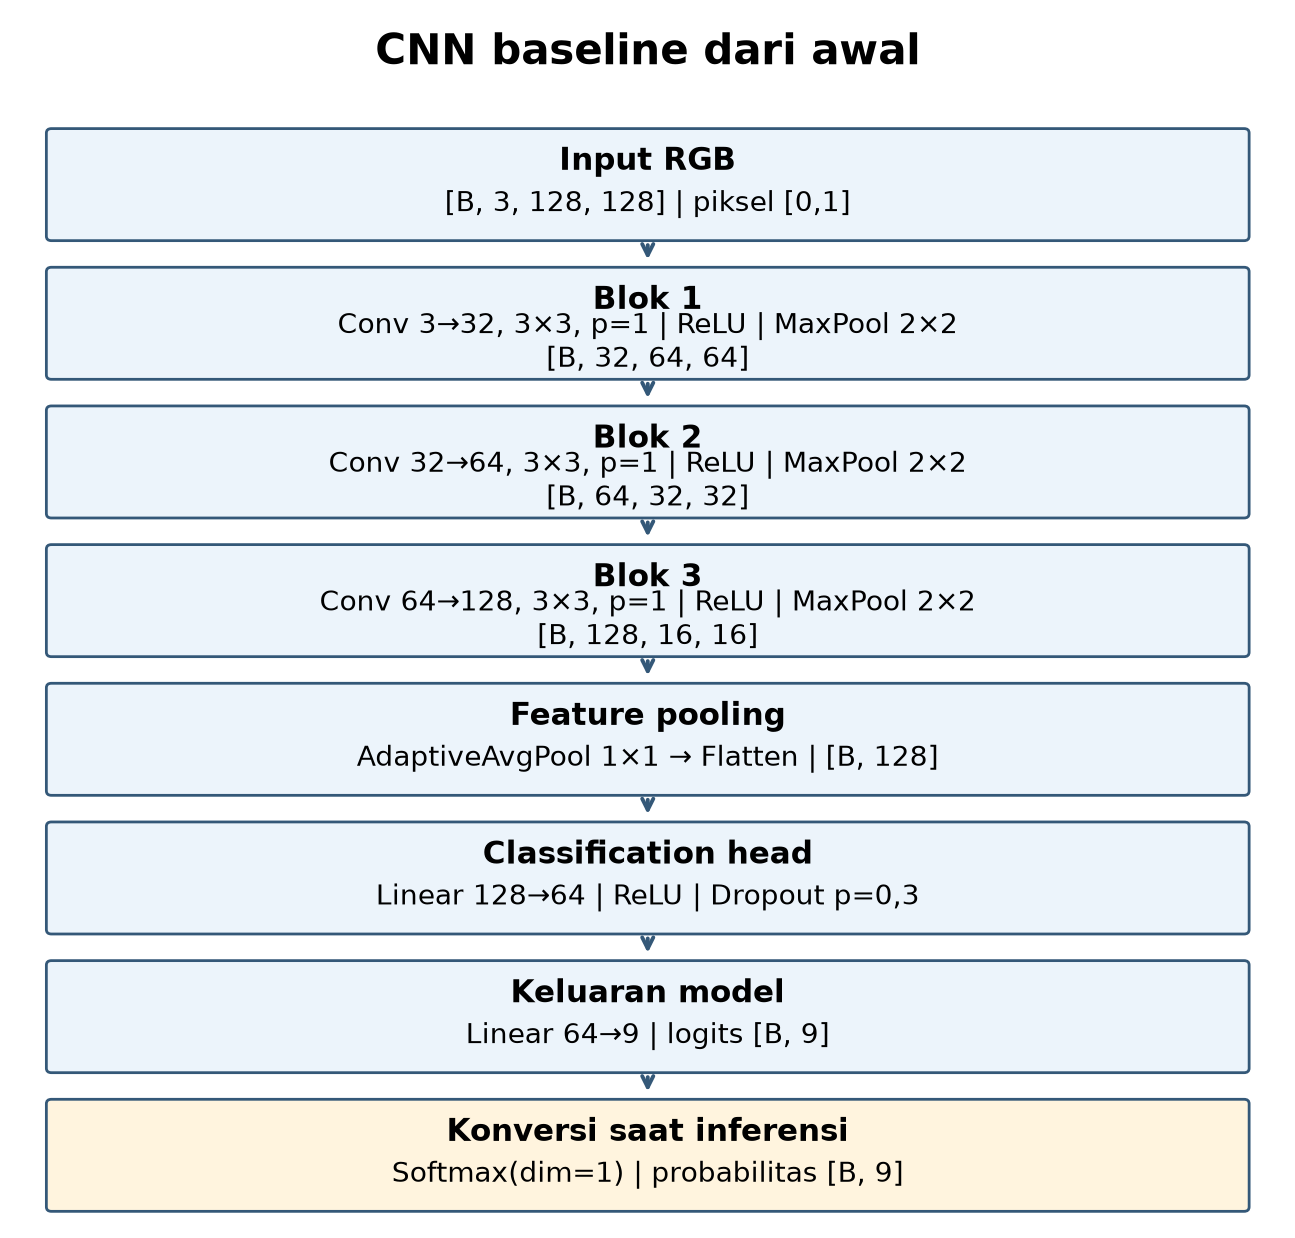

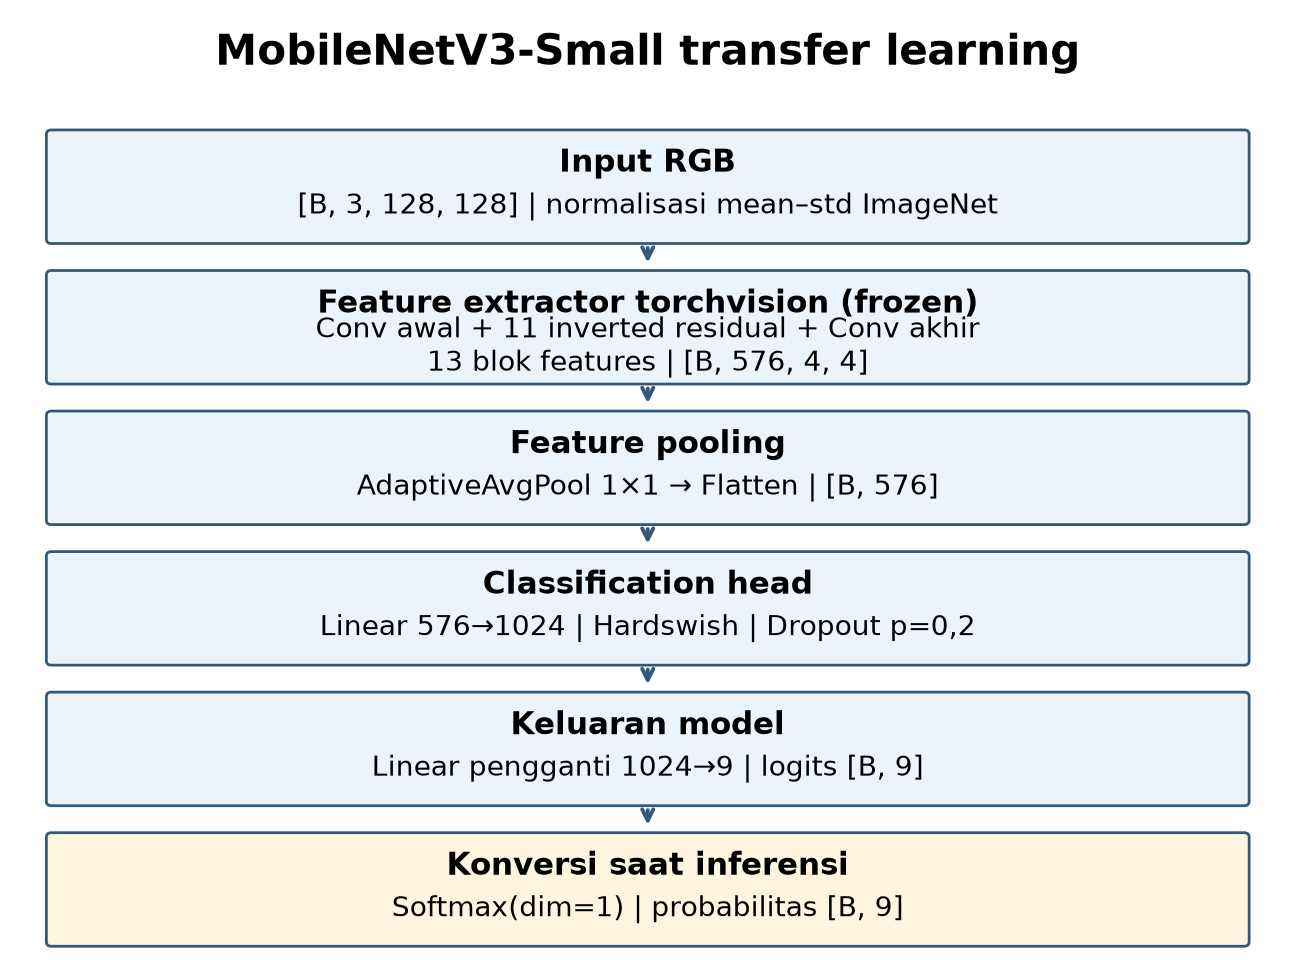

In [7]:
from IPython.display import Image, display
for filename in ['cnn_baseline_architecture.png', 'mobilenetv3_small_architecture.png']:
    display(Image(filename=str(ROOT / 'figures' / filename), width=680))

## Rencana eksperimen dan batasan

Progres 4 memerlukan audit kandidat near-duplicate, split stratified group-aware 70/15/15 (3.326/713/713 hanya perkiraan; jumlah aktual mengikuti grup), dan pipeline input yang konsisten. Augmentasi hanya pada training; pembobotan dihitung dari training. Bandingkan kontrol tanpa/dengan augmentasi serta tanpa/dengan pembobotan, bukan mengaktifkan semuanya otomatis. Pantau loss dan akurasi serta precision/recall/F1 makro pada validasi; confusion matrix, selisih latih–validasi, waktu pelatihan dan Grad-CAM direncanakan kemudian. Testing hanya sekali setelah konfigurasi akhir.

Inisialisasi dan bentuk tensor terverifikasi; hasil ini tidak membuktikan kemampuan klasifikasi. Belum ada pelatihan, tuning, evaluasi dataset atau bobot pretrained yang dimuat. GPU tidak digunakan dan kapasitas pelatihan pada CPU 8 GB belum dibuktikan.

Referensi: [UCI RealWaste](https://archive.ics.uci.edu/dataset/908/realwaste), [torchvision MobileNetV3-Small](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html), [Searching for MobileNetV3](https://arxiv.org/abs/1905.02244).